# Exploración de PeruFoodNet

El objetivo es reconocer platos peruanos a partir de fotografías. Una clase es el nombre del plato asignado por la carpeta. Exploraremos los datos antes de entrenar. PeruFoodNet v3 se distribuye bajo [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/); cite la [fuente](https://data.mendeley.com/datasets/hxhbbm497d/3).

Un dataset es una colección de datos; aquí contiene 4.000 fotos de 40 platos. El manifiesto es una tabla con una fila por foto, su ruta, clase y partición.

In [1]:
from pathlib import Path
CODE_URL = "https://github.com/miguelsff/maestria-ia-uni-ciclo-2-redes-neuronales/releases/download/v1.0-final/Equipo3_Codigo.zip"
DATASET_URL = "https://data.mendeley.com/public-api/zip/hxhbbm497d/download/3"
DATASET_ROOT = Path("E:/Dataset PeruFoodNet")
PROJECT_OVERRIDE = None  # Ruta opcional del proyecto
DOWNLOAD_DIR = Path("/content/perufoodnet_data") if Path("/content").is_dir() else Path.home() / "perufoodnet_data"


In [2]:
import sys
import zipfile
from urllib.request import urlretrieve
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False
candidatos = [Path.cwd(), *Path.cwd().parents]
if PROJECT_OVERRIDE is not None:
    candidatos.insert(0, Path(PROJECT_OVERRIDE))
proyectos = [p for base in candidatos for p in (base, base / "examen-final" / "entregables" / "3.3 Código")
             if (p / "src" / "predict.py").is_file()]
if not proyectos and EN_COLAB:
    destino = Path("/content/perufoodnet_codigo")
    destino.mkdir(parents=True, exist_ok=True)
    archivo = destino / "codigo.zip"
    urlretrieve(CODE_URL, archivo)
    with zipfile.ZipFile(archivo) as paquete:
        for miembro in paquete.infolist():
            if not (destino / miembro.filename).resolve().is_relative_to(destino.resolve()):
                raise ValueError("El paquete contiene una ruta fuera de su carpeta.")
        paquete.extractall(destino)
    proyectos = [p.parent.parent for p in destino.rglob("predict.py") if p.parent.name == "src"]
if not proyectos:
    raise FileNotFoundError("No se encontró el proyecto. Configure PROJECT_OVERRIDE.")
PROJECT = proyectos[0].resolve()
sys.path.insert(0, str(PROJECT / "src"))
print("Proyecto encontrado.")


Proyecto encontrado.


## Recursos
Se usa primero la copia local. Si falta, el programa descarga el ZIP desde el enlace configurado y busca su carpeta interna `Dataset PeruFoodNet`. Acepta enlaces HTTP directos o públicos de Google Drive. En Colab indique la ruta del proyecto en `PROJECT_OVERRIDE` si es necesario.

In [3]:
if EN_COLAB:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pandas==3.1.0", "matplotlib==3.11.2", "pillow==12.3.0", "gdown==5.2.0"])
from resources import resolve_dataset
DATASET_ROOT = resolve_dataset(DATASET_ROOT, DATASET_URL, DOWNLOAD_DIR)
MANIFEST = PROJECT / "data/manifest.csv"
CLASSES = PROJECT / "data/classes.json"
print("Datos preparados.")


Datos preparados.


## Etiquetas y distribución
El manifiesto asocia cada ruta con un índice de clase. Los conteos esperados son 100 imágenes por cada una de las 40 clases. La primera tabla muestra ejemplos de filas; la segunda cuenta fotografías por clase.

In [4]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
rows = pd.read_csv(MANIFEST)
classes = json.loads(CLASSES.read_text(encoding="utf-8-sig"))
print("Imágenes:", len(rows), "Clases:", len(classes))
display(rows.head().rename(columns={"relative_path": "ruta", "class_name": "clase", "class_index": "índice", "image_number": "número", "split": "partición"}))
display(rows.groupby("class_name").size().rename("imágenes").to_frame())

Imágenes: 4000 Clases: 40


,ruta,clase,índice,número,partición,subset_10,subset_40
0,Aguadito/01_Aguadito.jpg,Aguadito,0,1,train,1,1
1,Aguadito/02_Aguadito.jpg,Aguadito,0,2,train,1,1
2,Aguadito/03_Aguadito.jpg,Aguadito,0,3,train,1,1
3,Aguadito/04_Aguadito.jpg,Aguadito,0,4,train,1,1
4,Aguadito/05_Aguadito.jpg,Aguadito,0,5,train,1,1


,imágenes
class_name,
Aguadito,100
Aji de Gallina,100
Anticuchos,100
Arroz Chaufa,100
Arroz Tapado,100
Arroz con Mariscos,100
Arroz con Pollo,100
Bisteck a lo Pobre,100
Caldo de Gallina,100


## Ejemplos de entrenamiento: comparación por clase

Cada fila reúne dos fotos de la misma clase; compare también las filas para observar diferencias entre platos. Se eligen de forma determinista las primeras cuatro clases de `classes.json` y, en cada una, las imágenes 01 y 40 del manifiesto de entrenamiento. Los números identifican fotografías, no su calidad ni una secuencia temporal. Esta muestra no es una auditoría exhaustiva de etiquetas.


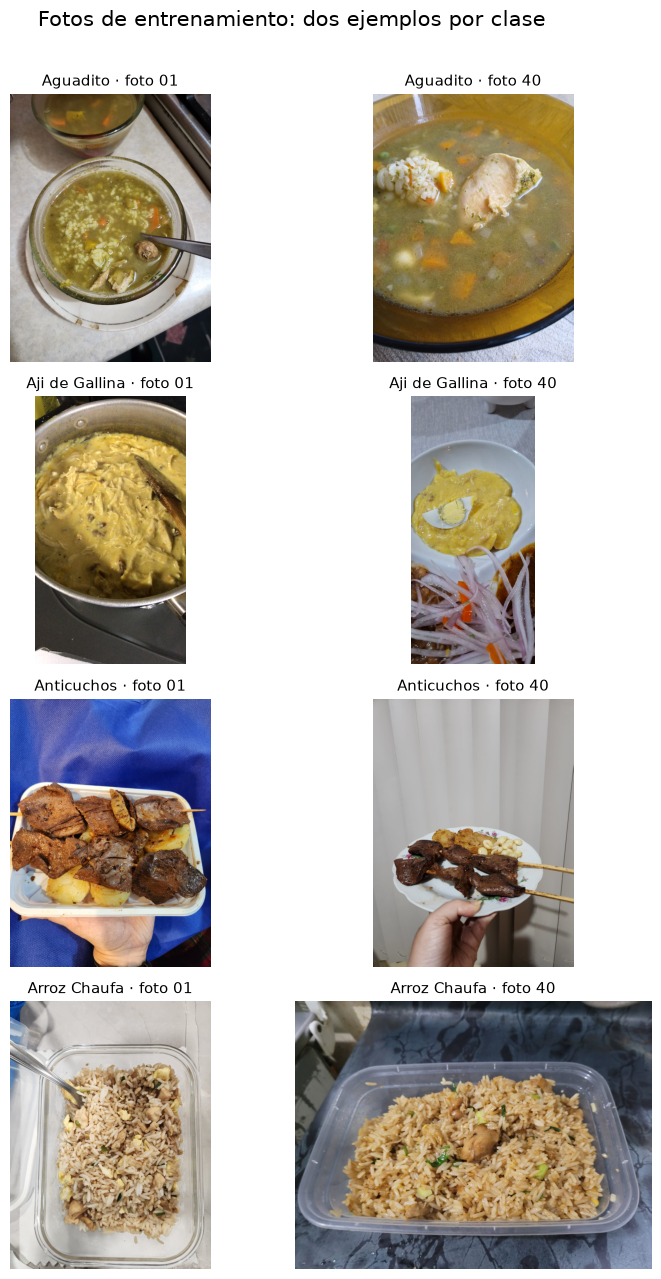

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(8, 13))
fig.suptitle("Fotos de entrenamiento: dos ejemplos por clase", fontsize=15)
for fila, clase in enumerate(classes[:4]):
    for columna, numero in enumerate((1, 40)):
        seleccion = rows[(rows.class_name == clase) & (rows.split == "train") &
                         (rows.image_number == numero)]
        if len(seleccion) != 1:
            raise ValueError(f"Se esperaba una foto {numero:02d} de {clase}")
        with Image.open(DATASET_ROOT / seleccion.iloc[0].relative_path) as image:
            axes[fila, columna].imshow(image.convert("RGB"))
        axes[fila, columna].set_title(f"{clase} · foto {numero:02d}", fontsize=11)
        axes[fila, columna].axis("off")
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()


En esta muestra, el ají de gallina aparece en una olla en la foto 01 y servido en un plato en la foto 40. La presentación y el encuadre varían incluso dentro de una misma clase; estas ocho imágenes no representan toda su variabilidad.

## Tamaño y calidad básica
Las dimensiones originales pueden variar; el modelo las ajustará a 224 × 224. La comprobación identifica imágenes que PIL no puede abrir, no errores semánticos ni duplicados.

In [6]:
sizes, errors = [], []
for path in rows.relative_path:
    try:
        with Image.open(DATASET_ROOT / path) as image:
            sizes.append(image.size)
            image.verify()
    except Exception as exc:
        errors.append((path, str(exc)))
print("Errores de lectura:", len(errors), errors[:5])
display(pd.DataFrame(sizes, columns=["ancho", "alto"]).describe())

Errores de lectura: 0 []


,ancho,alto
count,4000.000000,4000.000000
mean,1268.959250,1478.024750
std,266.619788,298.917029
min,265.000000,185.000000
25%,1200.000000,1200.000000
50%,1200.000000,1600.000000
75%,1200.000000,1600.000000
max,5312.000000,4270.000000


## Partición secuencial
Por clase, 01–70 se reserva para entrenamiento, 71–85 para prueba y 86–100 para validación. Los experimentos de entrenamiento usan 01–10 o 01–40 de entrenamiento, por lo que el conjunto de 10 está incluido en el de 40. La validación permite comparar configuraciones; la prueba se reserva para el ganador. Un presupuesto es la cantidad de fotos de entrenamiento por clase. La tabla muestra los conteos por clase y partición; el anidamiento verdadero indica que el presupuesto pequeño está incluido en el mayor.

In [7]:
display(pd.crosstab(rows.class_name, rows.split).rename_axis("clase").rename(columns={"train": "entrenamiento", "val": "validación", "test": "prueba"}))
print("Subconjuntos de entrenamiento:", int(rows.subset_10.sum()), int(rows.subset_40.sum()))
print("Anidamiento:", bool((rows.subset_10 <= rows.subset_40).all()))

split,prueba,entrenamiento,validación
clase,,,
Aguadito,15,70,15
Aji de Gallina,15,70,15
Anticuchos,15,70,15
Arroz Chaufa,15,70,15
Arroz Tapado,15,70,15
Arroz con Mariscos,15,70,15
Arroz con Pollo,15,70,15
Bisteck a lo Pobre,15,70,15
Caldo de Gallina,15,70,15


Subconjuntos de entrenamiento: 400 1600
Anidamiento: True


## Interpretación y límites
La división separa archivos, pero tomas de una misma ración podrían aparecer en distintas particiones. Esa correlación puede elevar las métricas; las conclusiones se limitan a esta partición. Este cuaderno no entrena ni evalúa modelos.